In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    classification_report,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC


In [2]:
DATA_DIR = Path("data")
DATA_FILE = DATA_DIR / "diabetes_prediction_dataset.csv"
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f"Could not find {DATA_FILE}. Run this notebook from its folder "
        "or update DATA_DIR to the sibling data folder."
    )
df = pd.read_csv(DATA_FILE)
target = "diabetes"
numeric_features = [
    "age",
    "hypertension",
    "heart_disease",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level",
]
categorical_features = ["gender", "smoking_history"]
features = numeric_features + categorical_features
required_columns = features + [target]
if missing := set(required_columns) - set(df.columns):
    raise ValueError(f"Dataset is missing columns: {sorted(missing)}")
if df[target].isna().any() or set(df[target].unique()) != {0, 1}:
    raise ValueError("diabetes must contain both binary labels 0 and 1 without missing values")
X = df[features]
y = df[target].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
print(f"Rows: {len(df)}; training rows: {len(X_train)}; test rows: {len(X_test)}")
print("Target counts:", y.value_counts().sort_index().to_dict())
df.head()


Rows: 100000; training rows: 80000; test rows: 20000
Target counts: {0: 91500, 1: 8500}


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [3]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            numeric_features,
        ),
        (
            "categorical",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            categorical_features,
        ),
    ]
)
# LinearSVC scales much better than kernel SVC on this 100,000-row dataset.
svm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LinearSVC(C=1.0, class_weight="balanced", random_state=42, max_iter=5000),
        ),
    ]
)
svm_model.fit(X_train, y_train)
print("SVM training complete.")


SVM training complete.


Balanced accuracy: 0.891
ROC AUC: 0.963
Classification report:
              precision    recall  f1-score   support

 No diabetes       0.99      0.89      0.94     18300
    Diabetes       0.43      0.89      0.58      1700

    accuracy                           0.89     20000
   macro avg       0.71      0.89      0.76     20000
weighted avg       0.94      0.89      0.91     20000



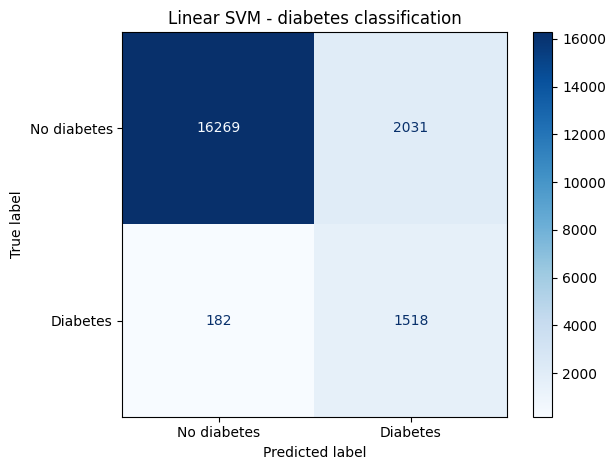

In [4]:
y_pred = svm_model.predict(X_test)
y_scores = svm_model.decision_function(X_test)
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"ROC AUC: {roc_auc_score(y_test, y_scores):.3f}")
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["No diabetes", "Diabetes"]))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No diabetes", "Diabetes"],
    cmap="Blues",
)
plt.title("Linear SVM - diabetes classification")
plt.tight_layout()
plt.show()
